In [5]:
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn import metrics
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

In [6]:
df = pd.read_excel("nba_baru.xlsx")
df

,Unnamed: 0,Name,Team,Number,Position,Age,Height,Weight,College,Salary,Salarymissing,Collegemissing
0,0,Avery Bradley,Boston Celtics,0,PG,25,74,180,Texas,7730337,False,False
1,1,Jae Crowder,Boston Celtics,99,SF,25,78,235,Marquette,6796117,False,False
2,2,John Holland,Boston Celtics,30,SG,27,77,205,Boston University,2839073,True,False
3,3,R.J. Hunter,Boston Celtics,28,SG,22,77,185,Georgia State,1148640,False,False
4,4,Jonas Jerebko,Boston Celtics,8,PF,29,82,231,Kentucky,5000000,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
452,452,Trey Lyles,Utah Jazz,41,PF,20,82,234,Kentucky,2239800,False,False
453,453,Shelvin Mack,Utah Jazz,8,PG,26,75,203,Butler,2433333,False,False
454,454,Raul Neto,Utah Jazz,25,PG,24,73,179,Kentucky,900000,False,True
455,455,Tibor Pleiss,Utah Jazz,21,C,26,87,256,Kentucky,2900000,False,True


In [7]:
features1 = ["Height", "Weight"]

data = df [features1].copy()
data

,Height,Weight
0,74,180
1,78,235
2,77,205
3,77,185
4,82,231
...,...,...
452,82,234
453,75,203
454,73,179
455,87,256


In [32]:
# Compute DBSCAN
db = DBSCAN(eps=5, min_samples=5).fit(data)
core_samples_mask = np.zeros_like(db.labels_, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True
labels = db.labels_
labels

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0

In [33]:
# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)
n_noise_

3

In [34]:
print('Perkiraaan jumlah klaster: %d' % n_clusters_)
print('Jumlah titik noise: %d' % n_noise_)
print("Silhouette Coefficient: %0.3f"
      % metrics.silhouette_score(data, labels))

Perkiraaan jumlah klaster: 1
Jumlah titik noise: 3
Silhouette Coefficient: 0.533


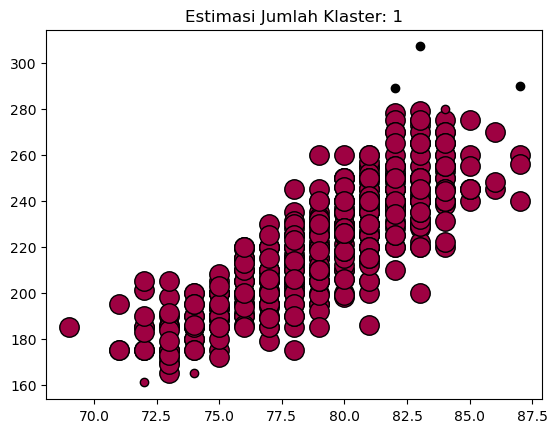

In [27]:
import matplotlib.pyplot as plt
%matplotlib inline

# Black removed and is used for noise instead.
unique_labels = set(labels)
colors = [plt.cm.Spectral(each)
          for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Black used for noise.
        col = [0, 0, 0, 1]

    class_member_mask = (labels == k)

    xy = data[class_member_mask & core_samples_mask]
    plt.plot(xy.iloc[:, 0], xy.iloc[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=14)

    xy = data[class_member_mask & ~core_samples_mask]
    plt.plot(xy.iloc[:, 0], xy.iloc[:, 1], 'o', markerfacecolor=tuple(col),
             markeredgecolor='k', markersize=6)

plt.title('Estimasi Jumlah Klaster: %d' % n_clusters_)
plt.show()

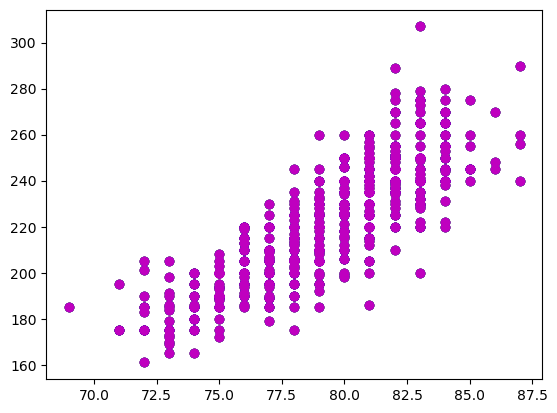

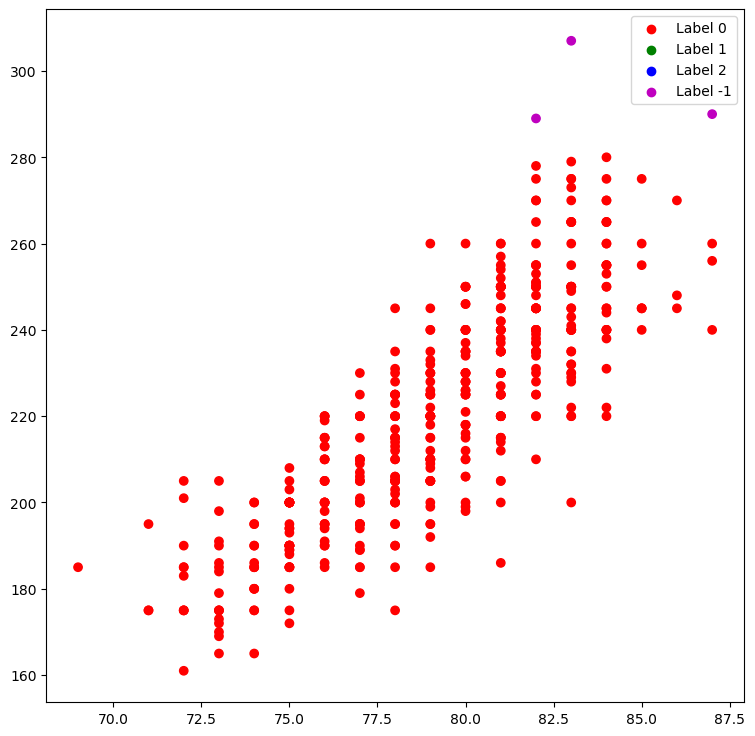

In [28]:
#Visualisasi 
colours = {}
colours[0] = 'r'
colours[1] = 'g'
colours[2] = 'b'
colours[-1] = 'm'

# Building the colour vector for each data point
cvec = [colours[label] for label in labels]

# For the construction of the legend of the plot
r = plt.scatter(data.iloc[:, 0], data.iloc[:, 1], color ='r')
g = plt.scatter(data.iloc[:, 0], data.iloc[:, 1], color ='g')
b = plt.scatter(data.iloc[:, 0], data.iloc[:, 1], color ='b')
m = plt.scatter(data.iloc[:, 0], data.iloc[:, 1], color ='m')
  
# Plotting P1 on the X-Axis and P2 on the Y-Axis 
plt.figure(figsize =(9, 9))
plt.scatter(data.iloc[:, 0], data.iloc[:, 1], c = cvec)
  
# Building the legend
plt.legend((r, g, b, m), ('Label 0', 'Label 1', 'Label 2', 'Label -1'))
  
plt.show()